# 05 - Baseline Models: Seasonal Naive and SARIMA

In this notebook I build the two simple models:
- **Seasonal naive:** the forecast is the load at the same hour last week. No training. Every other model must beat this.
- **SARIMA:** a classical statistical model that learns from the load series itself.

Both use only the past load (no calendar or temperature features). I use the `statsforecast` library.

### 1. Import libraries and load the data

In [1]:
import os
import time

import pandas as pd
import matplotlib.pyplot as plt
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, AutoARIMA, ARIMA

forecast_folder = "../results/forecasts"
tables_folder = "../results/tables"
figures_folder = "../results/figures"
os.makedirs(forecast_folder, exist_ok=True)
os.makedirs(tables_folder, exist_ok=True)

In [2]:
data = pd.read_csv("../datasets/processed/gb_features_2015_2019.csv")

# the Nixtla libraries need three columns: unique_id, ds (time) and y (value to forecast)
df = pd.DataFrame()
df["unique_id"] = ["GB"] * len(data)
df["ds"] = pd.to_datetime(data["time"]).dt.tz_localize(None)   # time in UTC, without the time zone label
df["y"] = data["load"]

print("Rows:", len(df))
df.head()

Rows: 43656


,unique_id,ds,y
0,GB,2015-01-08 00:00:00,32593.0
1,GB,2015-01-08 01:00:00,31607.0
2,GB,2015-01-08 02:00:00,30136.0
3,GB,2015-01-08 03:00:00,29286.0
4,GB,2015-01-08 04:00:00,27746.0


### How the forecasts are made

The same setup is used for every model:
- The model is trained on data **before 2019**.
- Then, for **every day of 2019** (365 days), it forecasts the **next 24 hours** from midnight (UTC).
- Each day it uses the real data up to that midnight, but the model itself is not trained again.

This gives 365 × 24 = 8,760 forecasts for each model. The library function `cross_validation` does this for me.

### 2. Seasonal naive

In [3]:
start = time.time()

naive_model = StatsForecast(models=[SeasonalNaive(season_length=168)], freq="h")
naive_cv = naive_model.cross_validation(df=df, h=24, step_size=24, n_windows=365)

naive_seconds = time.time() - start
print("Time:", round(naive_seconds, 1), "seconds")
print("Forecasts:", len(naive_cv))
naive_cv.head()

Time: 0.0 seconds
Forecasts: 8760


,unique_id,ds,cutoff,y,SeasonalNaive
0,GB,2019-01-01 00:00:00,2018-12-31 23:00:00,27090.0,29173.0
1,GB,2019-01-01 01:00:00,2018-12-31 23:00:00,26958.0,27882.0
2,GB,2019-01-01 02:00:00,2018-12-31 23:00:00,24546.0,25943.0
3,GB,2019-01-01 03:00:00,2018-12-31 23:00:00,22100.0,24700.0
4,GB,2019-01-01 04:00:00,2018-12-31 23:00:00,21038.0,23836.0


In [4]:
naive_mae = (naive_cv["y"] - naive_cv["SeasonalNaive"]).abs().mean()
print("Seasonal naive MAE on 2019:", round(naive_mae), "MW")

Seasonal naive MAE on 2019: 1969 MW


### 3. SARIMA

SARIMA is slow on long series, so (as written in the proposal) I fit it on a recent window: the **last 8 weeks before 2019**.

#### Step 1: choose the model orders with AutoARIMA
AutoARIMA tries different (p, d, q)(P, D, Q) orders and picks the best one (lowest AICc). Season length is 24 hours.

In [5]:
window = 24 * 7 * 8   # 8 weeks of hours
before_2019 = df[df["ds"] < "2019-01-01"]
last_8_weeks = before_2019.tail(window)

print("Fitting AutoARIMA on", last_8_weeks["ds"].iloc[0], "to", last_8_weeks["ds"].iloc[-1])

start = time.time()
auto_model = StatsForecast(models=[AutoARIMA(season_length=24)], freq="h")
auto_model.fit(last_8_weeks)
auto_seconds = time.time() - start

print("Time:", round(auto_seconds), "seconds")

Fitting AutoARIMA on 2018-11-06 00:00:00 to 2018-12-31 23:00:00


Time: 112 seconds


In [6]:
# the chosen orders are stored as (p, q, P, Q, season length, d, D)
p, q, P, Q, m, d, D = auto_model.fitted_[0, 0].model_["arma"]

print(f"Chosen model: SARIMA({p},{d},{q})({P},{D},{Q})[{m}]")

Chosen model: SARIMA(3,0,1)(2,1,0)[24]


#### Step 2: forecast every day of 2019 with this model
I keep the chosen orders fixed. The model is fitted once on the 8 weeks before 2019, then used to forecast every day of 2019.

In [7]:
# 8 weeks before 2019 + the whole of 2019
sarima_data = df[df["ds"] >= last_8_weeks["ds"].iloc[0]]

start = time.time()
sarima_model = StatsForecast(
    models=[ARIMA(order=(p, d, q), seasonal_order=(P, D, Q), season_length=24, alias="SARIMA")],
    freq="h",
)
sarima_cv = sarima_model.cross_validation(df=sarima_data, h=24, step_size=24, n_windows=365, refit=False)
sarima_seconds = auto_seconds + (time.time() - start)

print("Total time (with AutoARIMA):", round(sarima_seconds), "seconds")
sarima_mae = (sarima_cv["y"] - sarima_cv["SARIMA"]).abs().mean()
print("SARIMA MAE on 2019:", round(sarima_mae), "MW")

Total time (with AutoARIMA): 156 seconds
SARIMA MAE on 2019: 1847 MW


### 4. Plot one week

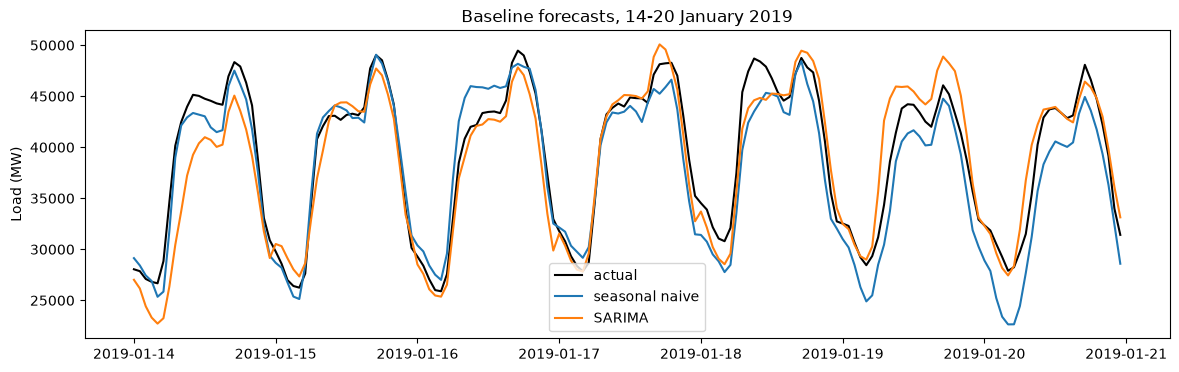

In [8]:
week = (naive_cv["ds"] >= "2019-01-14") & (naive_cv["ds"] < "2019-01-21")

plt.figure(figsize=(14, 4))
plt.plot(naive_cv[week]["ds"], naive_cv[week]["y"], label="actual", color="black")
plt.plot(naive_cv[week]["ds"], naive_cv[week]["SeasonalNaive"], label="seasonal naive")
plt.plot(sarima_cv[week]["ds"], sarima_cv[week]["SARIMA"], label="SARIMA")
plt.title("Baseline forecasts, 14-20 January 2019")
plt.ylabel("Load (MW)")
plt.legend()
plt.savefig(figures_folder + "/05_baselines_week.png")
plt.show()

### 5. Save the forecasts and times

In [9]:
def save_forecasts(cv, model_column, file_name):
    out = pd.DataFrame()
    out["time"] = cv["ds"]
    out["cutoff"] = cv["cutoff"]
    out["actual"] = cv["y"]
    out["forecast"] = cv[model_column]
    out.to_csv(forecast_folder + "/" + file_name, index=False)


save_forecasts(naive_cv, "SeasonalNaive", "seasonal_naive.csv")
save_forecasts(sarima_cv, "SARIMA", "sarima.csv")

times = pd.DataFrame({
    "model": ["Seasonal naive", "SARIMA"],
    "seconds": [naive_seconds, sarima_seconds],
})
times.to_csv(tables_folder + "/time_baselines.csv", index=False)
print("Saved")

Saved


### Summary

- Seasonal naive: no training, forecast = same hour last week
- SARIMA: orders chosen by AutoARIMA on the 8 weeks before 2019, then used for every day of 2019
- Forecasts saved in `results/forecasts/`

**Next:** notebook 06 - XGBoost.